# Bike Sharing Demand Analysis

**Project type:** Academic regression exercise · **Source period:** 2011–2012 · **Language:** English

This revised study preserves the historical project's goals—dataset description, data-quality checks, rental trends, user segmentation, weather and weekday comparisons, distributions, regression benchmarks, model interpretation, and a hyperparameter-search demonstration—while correcting methodological problems.

**Knowledge Base:**
- [Machine Learning](https://github.com/eduardojr-pereira/data-science-knowledge-base/tree/main/05_machine_learning)
- [Data Analysis & Visualization](https://github.com/eduardojr-pereira/data-science-knowledge-base/tree/main/02_data_analysis_visualization)

**Related References:**
- [Data Preparation and Pipelines — Technical Guide](https://github.com/eduardojr-pereira/data-science-knowledge-base/blob/main/05_machine_learning/reference_materials/04_preparacao_pipelines.pdf)
- [Validation and Optimization — Technical Guide](https://github.com/eduardojr-pereira/data-science-knowledge-base/blob/main/05_machine_learning/reference_materials/11_validacao_otimizacao.pdf)
- [Linear Regression — Technical Guide](https://github.com/eduardojr-pereira/data-science-knowledge-base/blob/main/05_machine_learning/reference_materials/12_regressao_linear.pdf)
- [Linear Regression — Cheat Sheet](https://github.com/eduardojr-pereira/data-science-knowledge-base/blob/main/05_machine_learning/cheat_sheets/cheat_sheet_regressao_linear.pdf)

> **Scope:** Contemporaneous weather features are observed on the same date as rental counts. This is **retrospective conditional demand estimation**, not a demonstrated operational day-ahead forecast.


## 1. Background, Questions, and Objectives

A bike-sharing service enables automated bicycle pickup and return at participating stations. Its rental records can support transportation planning and the study of mobility patterns. The historical source documentation describes how weather, seasonality, and calendar characteristics are associated with demand. Its original contextual claim of hundreds of systems worldwide referred to the dataset's historical publication period, not the current market.

The records represent the **Capital Bikeshare system in Washington, D.C.**, for calendar years 2011 and 2012; weather information was appended by the source dataset authors. The published UCI dataset provides both daily (`day.csv`) and hourly (`hour.csv`) aggregations. **Daily and hourly data are modeled in separate sections of this notebook**.

**Research questions:**
1. How does demand vary by year, month, weekday, season, and recorded weather conditions?
2. How do casual and registered riders contribute to observed rental activity?
3. Which predictors exhibit descriptive associations with demand?
4. How do several regression models compare on chronological cross-validation, and how does the selected model behave on a later holdout period?
5. At which hours do rider segments peak, and how do hourly patterns differ by day type?

**Success criteria:** Traceable data checks; meaningful visualizations; English explanations; preprocessing fitted inside training folds; a never-tuned-on chronological test; transparent results and limitations.


### 1.1. Source Data Dictionary

| Field | Source meaning | Analytical treatment |
|---|---|---|
| `instant` | Record index | Identifier; not a predictor |
| `dteday` | Date | Sorting and reporting; not fed directly to models |
| `season` | 1: spring, 2: summer, 3: fall, 4: winter | Descriptive factor; model exclusion to reduce redundant calendar encoding |
| `yr` | 0: 2011, 1: 2012 | Descriptive only, not used for extrapolation |
| `mnth` | Calendar month, 1–12 | Categorical predictor |
| `holiday` | 1 on a holiday, otherwise 0 | Binary predictor |
| `weekday` | 0: Sunday, 1: Monday, ..., 6: Saturday | Categorical predictor |
| `workingday` | 1 if neither a weekend nor holiday | Binary predictor |
| `weathersit` | Ordinal-coded weather situation, 1 through 4 | Categorical predictor |
| `temp` | Temperature normalized by 41 °C | Numeric predictor |
| `atemp` | Apparent temperature normalized by 50 °C | Descriptive only; excluded due to similarity with `temp` |
| `hum` | Relative humidity normalized by 100 | Numeric predictor |
| `windspeed` | Wind speed normalized by 67 | Numeric predictor |
| `casual` | Casual user rental count | Target component; **must not be a predictor** |
| `registered` | Registered user rental count | Target component; **must not be a predictor** |
| `cnt` | Total rentals (`casual` + `registered`) | Regression target |

The source documentation additionally identifies `hr` (0–23) in `hour.csv`; it is not present in the daily file. All categorical labels and units are taken from the included source documentation. The weekday mapping corrects the incorrect Monday-first mapping in the historical notebook.


## 2. Environment and Project Paths

All code, variable names, labels and comments are in English. The notebook requires the dependencies in `requirements.txt` and runs from either this project directory or the repository root. Raw data are read locally; nothing is downloaded during execution.


In [1]:
from pathlib import Path
import json
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

random_seed = 42
project_relative_path = Path('selected_projects/bike_sharing')
possible_project_directories = [Path.cwd(), Path.cwd() / project_relative_path]
project_directory = next((item for item in possible_project_directories
                          if (item / 'datasets' / 'day.csv').is_file()), None)
if project_directory is None:
    raise FileNotFoundError('Open the notebook from its project directory or the repository root.')
project_directory = project_directory.resolve()
if str(project_directory) not in sys.path:
    sys.path.insert(0, str(project_directory))
data_path = project_directory / 'datasets' / 'day.csv'
figures_directory = project_directory / 'outputs' / 'figures'
tables_directory = project_directory / 'outputs' / 'tables'
report_directory = project_directory / 'reports'
for directory in (figures_directory, tables_directory, report_directory):
    directory.mkdir(parents=True, exist_ok=True)
print({'python': platform.python_version(), 'pandas': pd.__version__,
       'scikit_learn': sklearn.__version__, 'project': project_directory.name})

{'python': '3.14.4', 'pandas': '3.1.1', 'scikit_learn': '1.9.1', 'project': 'bike_sharing'}


## 3. Data Loading and Integrity Checks

The source identifiers are retained for traceability. Integrity checks enforce record count, exact time coverage, absence of missing values and duplicate dates, and the accounting identity `casual + registered == cnt`.


In [2]:
raw_data = pd.read_csv(data_path, parse_dates=['dteday'])
expected_columns = {'instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
                    'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
                    'casual', 'registered', 'cnt'}
assert expected_columns.issubset(raw_data.columns), 'Unexpected source schema.'
assert len(raw_data) == 731, 'Unexpected daily record count.'
assert not raw_data.isna().any().any(), 'Missing values detected.'
assert not raw_data.duplicated(subset=['dteday']).any(), 'Duplicate dates detected.'
assert (raw_data['casual'] + raw_data['registered']).eq(raw_data['cnt']).all(), 'Invalid rental totals.'
assert ((raw_data['dteday'].dt.dayofweek + 1) % 7).eq(raw_data['weekday']).all(), 'Weekday mapping mismatch.'
assert raw_data['dteday'].min() == pd.Timestamp('2011-01-01')
assert raw_data['dteday'].max() == pd.Timestamp('2012-12-31')

bike_data = raw_data.sort_values('dteday').reset_index(drop=True)
assert bike_data['dteday'].diff().iloc[1:].eq(pd.Timedelta(days=1)).all(), 'Missing calendar days.'
print(f'Records: {len(bike_data):,} | Date range: '
      f"{bike_data['dteday'].min():%Y-%m-%d} to {bike_data['dteday'].max():%Y-%m-%d}")
print(f"Total rentals: {bike_data['cnt'].sum():,} | Missing values: {int(bike_data.isna().sum().sum())}")
bike_data.head()

Records: 731 | Date range: 2011-01-01 to 2012-12-31
Total rentals: 3,292,679 | Missing values: 0


/tmp/ipykernel_32941/517904367.py:10: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  assert ((raw_data['dteday'].dt.dayofweek + 1) % 7).eq(raw_data['weekday']).all(), 'Weekday mapping mismatch.'


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


### 3.1. Missing Values, Zeros, and Summary Statistics

Zeros are **not inherently missing values**. For example, `holiday == 0` means a non-holiday, `weekday == 0` means Sunday, and `workingday == 0` means a weekend or holiday. Zero counts in weather-derived measurements must be interpreted according to their field definitions and observed distribution.


In [3]:
missing_values = bike_data.isna().sum().rename('missing_count')
zero_counts = bike_data.select_dtypes(include='number').eq(0).sum().rename('zero_count')
data_quality = pd.concat([missing_values, zero_counts], axis=1).fillna(0).astype(int)
data_quality['zero_share_pct'] = (data_quality['zero_count'] / len(bike_data) * 100).round(2)
print('Missing and zero counts by variable:')
display(data_quality)
print('Descriptive statistics for rental counts and weather:')
display(bike_data[['casual', 'registered', 'cnt', 'temp', 'atemp', 'hum', 'windspeed']].describe().round(2))
print('Duplicate full rows:', int(bike_data.duplicated().sum()))


Missing and zero counts by variable:


,missing_count,zero_count,zero_share_pct
instant,0,0,0.00
dteday,0,0,0.00
season,0,0,0.00
yr,0,365,49.93
mnth,0,0,0.00
holiday,0,710,97.13
weekday,0,105,14.36
workingday,0,231,31.60
weathersit,0,0,0.00
temp,0,0,0.00


Descriptive statistics for rental counts and weather:


,casual,registered,cnt,temp,atemp,hum,windspeed
count,731.00,731.00,731.00,731.00,731.00,731.00,731.00
mean,848.18,3656.17,4504.35,0.50,0.47,0.63,0.19
std,686.62,1560.26,1937.21,0.18,0.16,0.14,0.08
min,2.00,20.00,22.00,0.06,0.08,0.00,0.02
25%,315.50,2497.00,3152.00,0.34,0.34,0.52,0.13
50%,713.00,3662.00,4548.00,0.50,0.49,0.63,0.18
75%,1096.00,4776.50,5956.00,0.66,0.61,0.73,0.23
max,3410.00,6946.00,8714.00,0.86,0.84,0.97,0.51


Duplicate full rows: 0


## 4. Exploratory Data Analysis (EDA)

Exploration describes historical patterns and does **not establish causality**. The total rental count is a sum of rider types, so `casual` and `registered` are useful for descriptive plots but never permitted in the model input matrix.


### 4.1. Total Rentals and Rider Segmentation

The source notebook explored both the total number of rentals and the share attributable to casual versus registered users. We preserve those measures and extend the time comparison.


Total rentals: 3,292,679


,rider_type,total_rentals,share_pct
0,Casual,620017,18.83
1,Registered,2672662,81.17


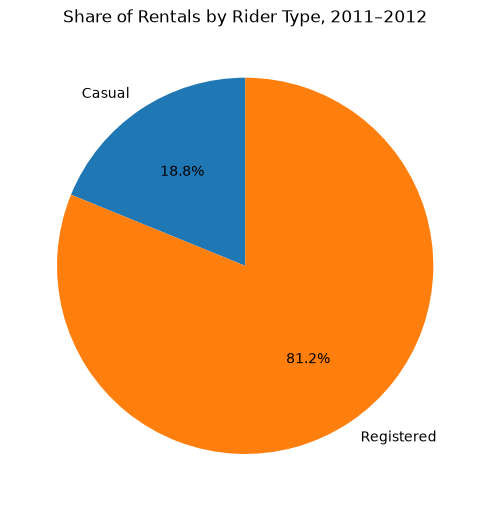

In [4]:
rental_totals = bike_data[['casual', 'registered', 'cnt']].sum().astype(int)
rider_breakdown = pd.DataFrame({
    'rider_type': ['Casual', 'Registered'],
    'total_rentals': [int(rental_totals['casual']), int(rental_totals['registered'])],
})
rider_breakdown['share_pct'] = rider_breakdown['total_rentals'] / rental_totals['cnt'] * 100
assert int(rider_breakdown['total_rentals'].sum()) == int(rental_totals['cnt'])
print('Total rentals:', f"{int(rental_totals['cnt']):,}")
display(rider_breakdown.round(2))
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
ax.pie(rider_breakdown['total_rentals'], labels=rider_breakdown['rider_type'],
       autopct='%1.1f%%', startangle=90)
ax.set_title('Share of Rentals by Rider Type, 2011–2012')
fig.savefig(figures_directory / 'rider_type_mix.png', dpi=150, bbox_inches='tight')
plt.show()


### 4.2. Daily Trends, Yearly and Monthly Comparison

The chronological plot shows three distinct series: total, registered and casual rentals. Month-by-month averages and yearly totals highlight seasonality and differences between 2011 and 2012. The overall pattern does not by itself identify a causal mechanism.


Annual totals and average daily rentals:


,sum,mean
year,,
2011,1243103,3405.8
2012,2049576,5599.9


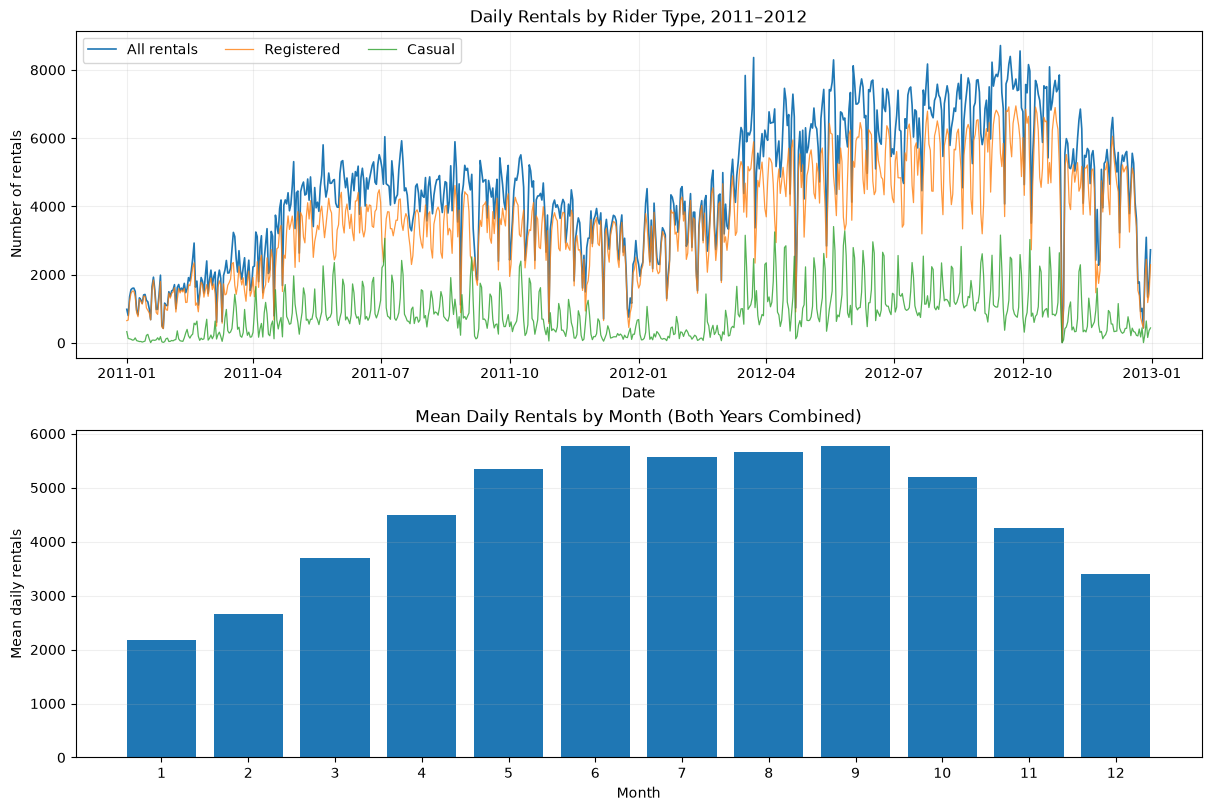

In [5]:
annual_summary = bike_data.groupby(bike_data['dteday'].dt.year)['cnt'].agg(['sum', 'mean'])
monthly_summary = bike_data.groupby(bike_data['dteday'].dt.month)['cnt'].mean()
print('Annual totals and average daily rentals:')
display(annual_summary.rename_axis('year').round(1))

fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
axes[0].plot(bike_data['dteday'], bike_data['cnt'], label='All rentals', linewidth=1.2)
axes[0].plot(bike_data['dteday'], bike_data['registered'], label='Registered', linewidth=0.9, alpha=0.8)
axes[0].plot(bike_data['dteday'], bike_data['casual'], label='Casual', linewidth=0.9, alpha=0.8)
axes[0].set(title='Daily Rentals by Rider Type, 2011–2012', xlabel='Date', ylabel='Number of rentals')
axes[0].legend(ncol=3)
axes[0].grid(alpha=0.2)
axes[1].bar(monthly_summary.index, monthly_summary.to_numpy())
axes[1].set(title='Mean Daily Rentals by Month (Both Years Combined)', xlabel='Month',
            ylabel='Mean daily rentals', xticks=list(range(1, 13)))
axes[1].grid(axis='y', alpha=0.2)
fig.savefig(figures_directory / 'demand_patterns.png', dpi=150, bbox_inches='tight')
plt.show()


### 4.3. Weather Conditions and Rental Demand

Source weather codes: **1** (clear/few clouds), **2** (mist/cloud cover), **3** (light snow or rain), **4** (heavy precipitation/mist). These are observational group comparisons; the group sizes differ, and a group with few days should not be overinterpreted.


,days,total_rentals,mean_rentals
weathersit,,,
Clear / few clouds,463,2257952,4876.8
Mist / cloudy,247,996858,4035.9
Light rain / snow,21,37869,1803.3


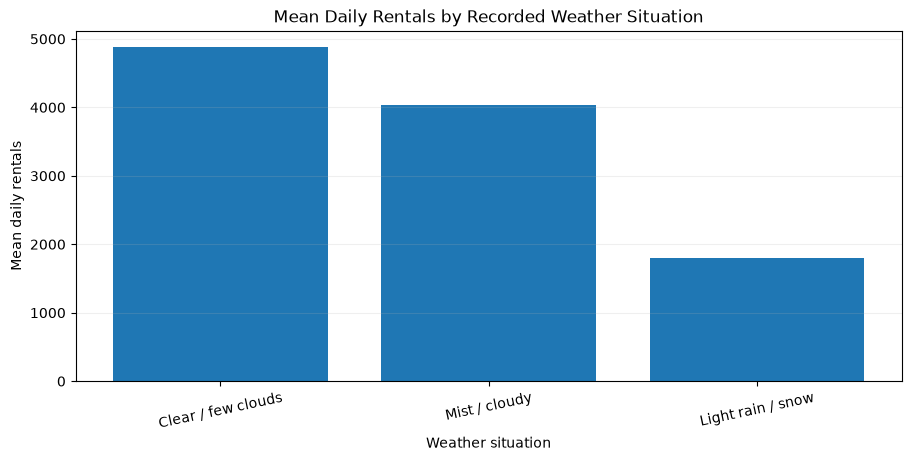

In [6]:
weather_labels = {1: 'Clear / few clouds', 2: 'Mist / cloudy',
                  3: 'Light rain / snow', 4: 'Heavy precipitation'}
weather_summary = (bike_data.groupby('weathersit')['cnt']
                   .agg(days='count', total_rentals='sum', mean_rentals='mean')
                   .rename(index=weather_labels))
display(weather_summary.round(1))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
ax.bar(weather_summary.index.astype(str), weather_summary['mean_rentals'])
ax.set(title='Mean Daily Rentals by Recorded Weather Situation',
       xlabel='Weather situation', ylabel='Mean daily rentals')
ax.tick_params(axis='x', labelrotation=12)
ax.grid(axis='y', alpha=0.2)
fig.savefig(figures_directory / 'rentals_by_weather.png', dpi=150, bbox_inches='tight')
plt.show()


### 4.4. Weekday, Working-Day, Holiday, and Season Patterns

The UCI daily file encodes Sunday as `weekday == 0`. We show weekly averages in Sunday-first order and retain the source's holiday and season semantics, correcting the mislabeled weekdays in the original notebook.


Working-day comparison (1 = working day):


,count,mean
workingday,,
0,231,4330.2
1,500,4584.8


Holiday comparison (1 = holiday):


,count,mean
holiday,,
0,710,4527.1
1,21,3735.0


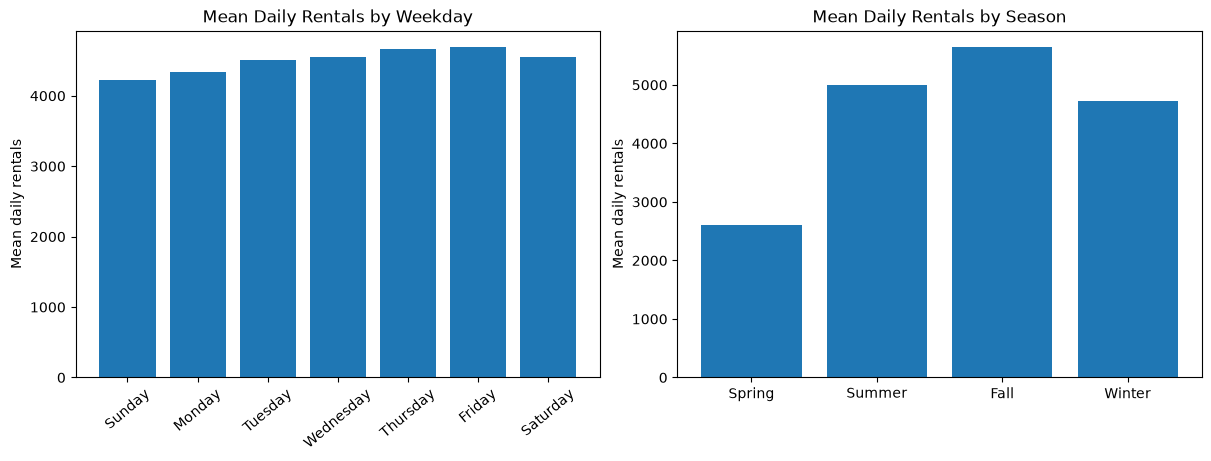

In [7]:
weekday_labels = ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']
weekday_mean = bike_data.groupby('weekday')['cnt'].mean().reindex(range(7))
workday_summary = bike_data.groupby('workingday')['cnt'].agg(['count', 'mean'])
holiday_summary = bike_data.groupby('holiday')['cnt'].agg(['count', 'mean'])
season_labels = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
season_mean = bike_data.groupby('season')['cnt'].mean().rename(index=season_labels)
print('Working-day comparison (1 = working day):')
display(workday_summary.round(1))
print('Holiday comparison (1 = holiday):')
display(holiday_summary.round(1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].bar(weekday_labels, weekday_mean.to_numpy())
axes[0].set(title='Mean Daily Rentals by Weekday', ylabel='Mean daily rentals')
axes[0].tick_params(axis='x', labelrotation=40)
axes[1].bar(season_mean.index.astype(str), season_mean.to_numpy())
axes[1].set(title='Mean Daily Rentals by Season', ylabel='Mean daily rentals')
fig.savefig(figures_directory / 'weekday_and_season.png', dpi=150, bbox_inches='tight')
plt.show()


### 4.5. Correlations and Distributions

The historical notebook included a large scatter-matrix and correlation analysis. Here we use focused plots: numerical predictors against the target, a correlation heatmap, and distributions by weather/season. Because `cnt = casual + registered`, their high correlation with `cnt` is an arithmetic identity—not evidence of valid predictive features. They are omitted from the predictor correlation display.


,cnt,temp,atemp,hum,windspeed,mnth,season,workingday
cnt,1.000,0.627,0.631,-0.101,-0.235,0.280,0.406,0.061
temp,0.627,1.000,0.992,0.127,-0.158,0.220,0.334,0.053
atemp,0.631,0.992,1.000,0.140,-0.184,0.227,0.343,0.052
hum,-0.101,0.127,0.140,1.000,-0.248,0.222,0.205,0.024
windspeed,-0.235,-0.158,-0.184,-0.248,1.000,-0.208,-0.229,-0.019
mnth,0.280,0.220,0.227,0.222,-0.208,1.000,0.831,-0.006
season,0.406,0.334,0.343,0.205,-0.229,0.831,1.000,0.012
workingday,0.061,0.053,0.052,0.024,-0.019,-0.006,0.012,1.000


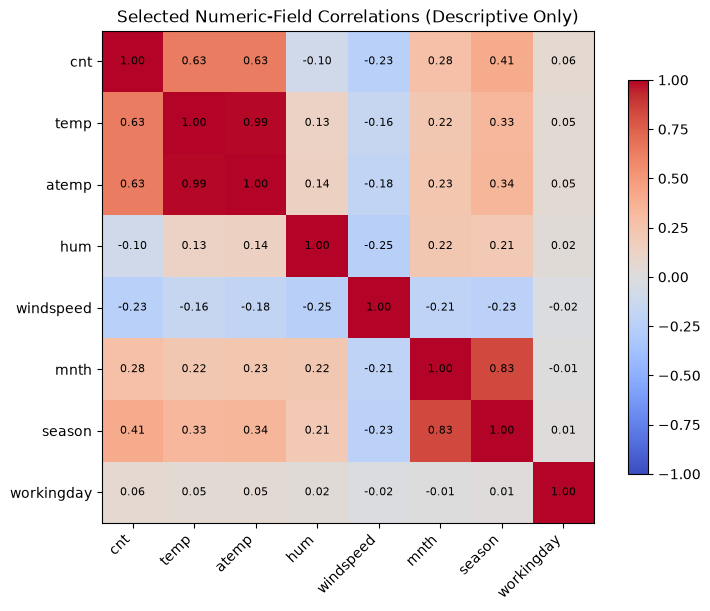

In [8]:
exploration_columns = ['cnt', 'temp', 'atemp', 'hum', 'windspeed', 'mnth', 'season', 'workingday']
correlation_matrix = bike_data[exploration_columns].corr(numeric_only=True)
display(correlation_matrix.round(3))
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
image = ax.imshow(correlation_matrix, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(exploration_columns)), labels=exploration_columns, rotation=45, ha='right')
ax.set_yticks(range(len(exploration_columns)), labels=exploration_columns)
for row in range(len(exploration_columns)):
    for col in range(len(exploration_columns)):
        ax.text(col, row, f'{correlation_matrix.iloc[row, col]:.2f}',
                ha='center', va='center', fontsize=8)
ax.set_title('Selected Numeric-Field Correlations (Descriptive Only)')
fig.colorbar(image, ax=ax, shrink=0.8)
fig.savefig(figures_directory / 'correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


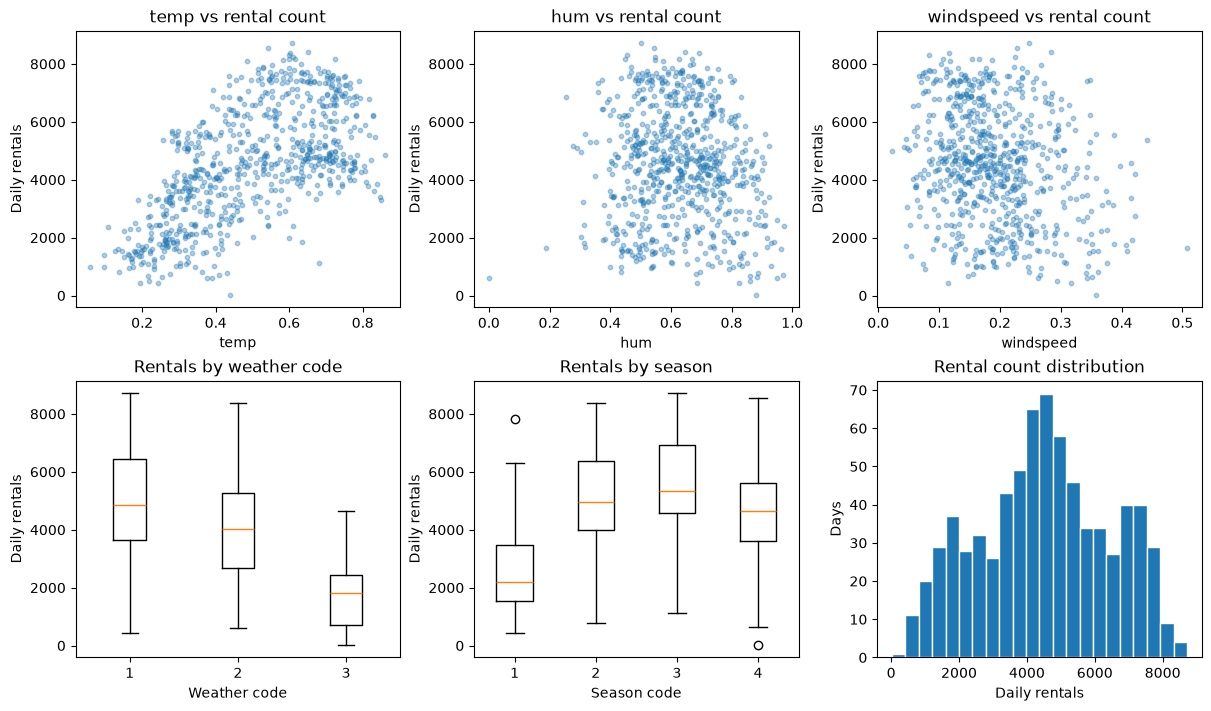

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True)
for ax, column in zip(axes.flat[:3], ['temp', 'hum', 'windspeed']):
    ax.scatter(bike_data[column], bike_data['cnt'], s=10, alpha=0.35)
    ax.set(xlabel=column, ylabel='Daily rentals', title=f'{column} vs rental count')
axes[1, 0].boxplot([bike_data.loc[bike_data['weathersit'] == value, 'cnt']
                    for value in sorted(bike_data['weathersit'].unique())],
                   tick_labels=[str(value) for value in sorted(bike_data['weathersit'].unique())])
axes[1, 0].set(title='Rentals by weather code', xlabel='Weather code', ylabel='Daily rentals')
axes[1, 1].boxplot([bike_data.loc[bike_data['season'] == value, 'cnt']
                    for value in sorted(bike_data['season'].unique())],
                   tick_labels=[str(value) for value in sorted(bike_data['season'].unique())])
axes[1, 1].set(title='Rentals by season', xlabel='Season code', ylabel='Daily rentals')
axes[1, 2].hist(bike_data['cnt'], bins=22, edgecolor='white')
axes[1, 2].set(title='Rental count distribution', xlabel='Daily rentals', ylabel='Days')
fig.savefig(figures_directory / 'distributions.png', dpi=150, bbox_inches='tight')
plt.show()


### 4.6. Interpretation of Descriptive Findings

These descriptive plots preserve the source notebook's emphasis on data exploration and rider behavior. Compare average daily demand alongside group size: a visually extreme mean from a rare weather condition may be unstable. Monthly, temperature, season and calendar effects may overlap; simple comparisons are neither adjusted effects nor causal estimates.

The missing-value summary, descriptive statistics, correlations, histograms and boxplots give an inspectable exploratory analysis without an automatic profiling report.


## 5. Feature Engineering and Leakage Prevention

The original notebook normalized all observations **before** splitting into train and test, inadvertently leaking future distribution information into training. This version fits encoders, scalers and optional numeric polynomial features separately inside each training fold via scikit-learn `Pipeline`.

Excluded variables: `instant` (index), `dteday` (date key), `cnt` (target), `casual` and `registered` (target components), `yr` (two-year indicator unsuitable for extrapolation), `atemp` (correlated with `temp`), and `season` (overlaps with month encoding).


In [10]:
numeric_features = ['temp', 'hum', 'windspeed']
categorical_features = ['mnth', 'weekday', 'weathersit']
binary_features = ['holiday', 'workingday']
feature_names = numeric_features + categorical_features + binary_features

target = bike_data['cnt'].copy()
features = bike_data[feature_names].copy()
for column in categorical_features:
    features[column] = features[column].astype('category')
assert not {'cnt', 'casual', 'registered', 'instant', 'dteday'}.intersection(features.columns)
print('Predictors:', ', '.join(feature_names))

Predictors: temp, hum, windspeed, mnth, weekday, weathersit, holiday, workingday


## 6. Chronological Experimental Design

The earliest 80% of dates form the development period; the latest 20% form an untouched holdout. The development period is evaluated by an expanding-window `TimeSeriesSplit(n_splits=4)`; this respects chronology and avoids random training/test mixing. Model selection is based **only on development-period CV RMSE**.

**Important distinction:** This is an observational comparison using same-day weather, not a one-day-ahead operational forecast. The final holdout will be evaluated once after selecting a model.


In [11]:
train_end = int(len(bike_data) * 0.80)
features_train = features.iloc[:train_end].copy()
features_test = features.iloc[train_end:].copy()
target_train = target.iloc[:train_end].copy()
target_test = target.iloc[train_end:].copy()
test_dates = bike_data['dteday'].iloc[train_end:].copy()

assert bike_data.loc[train_end - 1, 'dteday'] < bike_data.loc[train_end, 'dteday']
cv_strategy = TimeSeriesSplit(n_splits=4)
for train_indices, validation_indices in cv_strategy.split(features_train):
    assert train_indices.max() < validation_indices.min()

print(f"Development: {bike_data['dteday'].iloc[0]:%Y-%m-%d} → "
      f"{bike_data['dteday'].iloc[train_end-1]:%Y-%m-%d} ({len(features_train)} days)")
print(f"Holdout:     {test_dates.iloc[0]:%Y-%m-%d} → "
      f"{test_dates.iloc[-1]:%Y-%m-%d} ({len(features_test)} days)")

Development: 2011-01-01 → 2012-08-06 (584 days)
Holdout:     2012-08-07 → 2012-12-31 (147 days)


## 7. Regression Benchmarks

The original work compared linear regression, polynomial regression, decision trees, random forests and SVR. We retain those model families, add a median baseline and a regularized linear model, and evaluate each using identical development folds.

**Metrics:** RMSE (primary selection metric), MAE (absolute errors) and R² (holdout interpretation). A **negative R²** means a model is worse on the evaluated sample than predicting that sample's mean; it is not evidence of production forecasting capability.


In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import GridSearchCV
from sklearn.tree import plot_tree


def make_pipeline(model, polynomial_degree=1):
    numeric_steps = [('scaling', StandardScaler())]
    if polynomial_degree > 1:
        numeric_steps.append(('polynomial_features', PolynomialFeatures(
            degree=polynomial_degree, include_bias=False)))
    preprocessing = ColumnTransformer(
        transformers=[
            ('numeric', Pipeline(numeric_steps), numeric_features),
            ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
            ('binary', 'passthrough', binary_features),
        ], remainder='drop', sparse_threshold=0,
    )
    return Pipeline([('preprocess', preprocessing), ('model', model)])

candidate_models = {
    'Median baseline': DummyRegressor(strategy='median'),
    'Linear regression': LinearRegression(),
    'Ridge regression': Ridge(alpha=20.0),
    'Polynomial ridge (degree 2)': Ridge(alpha=30.0),
    'Decision tree': DecisionTreeRegressor(max_depth=6, min_samples_leaf=8, random_state=random_seed),
    'Random forest': RandomForestRegressor(n_estimators=100, min_samples_leaf=5,
                                           max_features=0.85, random_state=random_seed, n_jobs=1),
    'SVR': SVR(C=1500.0, epsilon=200.0, gamma='scale'),
}


def candidate_pipeline(model_name):
    polynomial_degree = 2 if model_name == 'Polynomial ridge (degree 2)' else 1
    return make_pipeline(candidate_models[model_name], polynomial_degree=polynomial_degree)

cv_records = []
for model_name in candidate_models:
    estimator = candidate_pipeline(model_name)
    fold_scores = -cross_val_score(
        estimator, features_train, target_train, cv=cv_strategy,
        scoring='neg_root_mean_squared_error', n_jobs=1, error_score='raise'
    )
    cv_records.append({
        'model': model_name,
        'cv_mean_rmse': float(np.mean(fold_scores)),
        'cv_std_rmse': float(np.std(fold_scores, ddof=1)),
        'fold_rmse': [float(value) for value in fold_scores],
    })
cv_records.sort(key=lambda item: item['cv_mean_rmse'])
model_comparison = pd.DataFrame(cv_records).drop(columns='fold_rmse')
model_comparison.to_csv(tables_directory / 'model_comparison.csv', index=False)
display(model_comparison.round(2))


,model,cv_mean_rmse,cv_std_rmse
0,Polynomial ridge (degree 2),1431.31,559.37
1,Ridge regression,1516.75,545.64
2,Decision tree,1532.97,569.44
3,Random forest,1574.81,454.43
4,SVR,1584.97,548.34
5,Linear regression,1596.94,672.91
6,Median baseline,2054.65,906.47


### 7.1. Cross-Validation Error Distributions

The original compared training and test scores for multiple tuned models, repeatedly inspecting the test set. This version displays **development-fold** performance only; test results are reserved for the final selected model.


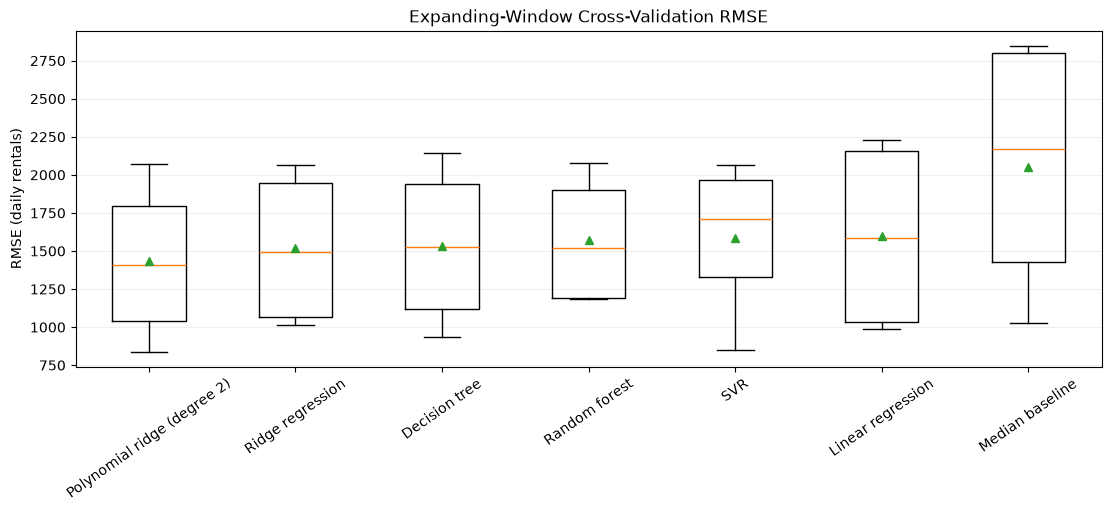

In [13]:
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
ax.boxplot([record['fold_rmse'] for record in cv_records],
           tick_labels=[record['model'] for record in cv_records], showmeans=True)
ax.set(title='Expanding-Window Cross-Validation RMSE', ylabel='RMSE (daily rentals)')
ax.tick_params(axis='x', labelrotation=35)
ax.grid(axis='y', alpha=0.2)
fig.savefig(figures_directory / 'cross_validation_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


### 7.2. Hyperparameter Optimization — Training-Only Demonstration

The historical notebook searched extensive grids but used ordinary shuffled K-fold and inspected test results repeatedly. We preserve the *learning objective* with two compact `GridSearchCV` experiments, **only on development data and time-aware CV**. These tuned models are **not included in the predefined model selection** or evaluated on the final holdout; tuning is shown as a separate methodological exercise.


In [14]:
tuning_experiments = {
    'Decision tree (tuned example)': (
        make_pipeline(DecisionTreeRegressor(random_state=random_seed)),
        {'model__max_depth': [4, 8], 'model__min_samples_leaf': [5, 10]},
    ),
    'Random forest (tuned example)': (
        make_pipeline(RandomForestRegressor(random_state=random_seed, n_jobs=1)),
        {'model__n_estimators': [50, 100], 'model__min_samples_leaf': [5, 10]},
    ),
}
tuning_records = []
for experiment_name, (estimator, search_grid) in tuning_experiments.items():
    parameter_search = GridSearchCV(estimator, search_grid, scoring='neg_root_mean_squared_error',
                                    cv=cv_strategy, n_jobs=1, refit=True, error_score='raise')
    parameter_search.fit(features_train, target_train)
    tuning_records.append({
        'experiment': experiment_name,
        'best_cv_rmse': -float(parameter_search.best_score_),
        'best_parameters': str(parameter_search.best_params_),
    })
print('Educational tuning exercise (no holdout evaluation):')
display(pd.DataFrame(tuning_records).round(2))


Educational tuning exercise (no holdout evaluation):


,experiment,best_cv_rmse,best_parameters
0,Decision tree (tuned example),1539.42,"{'model__max_depth': 8, 'model__min_samples_le..."
1,Random forest (tuned example),1523.59,"{'model__min_samples_leaf': 5, 'model__n_estim..."


### 7.3. Random Forest Interpretation: Feature Importance

The original visualized one tree and ranked random-forest feature importances. We retain these diagnostics, but fit the explanatory forest **using development data only**. Impurity-based importance is model-dependent, may be biased toward some variables, and **does not imply causal effect**. Encoded feature names come from the fitted preprocessing pipeline.


,feature,importance
0,numeric__temp,0.679
1,numeric__hum,0.152
2,numeric__windspeed,0.067
3,categorical__mnth_1,0.018
4,categorical__weathersit_1,0.014
5,categorical__mnth_6,0.011
6,categorical__weathersit_3,0.008
7,binary__workingday,0.008
8,categorical__mnth_5,0.006
9,categorical__mnth_3,0.006


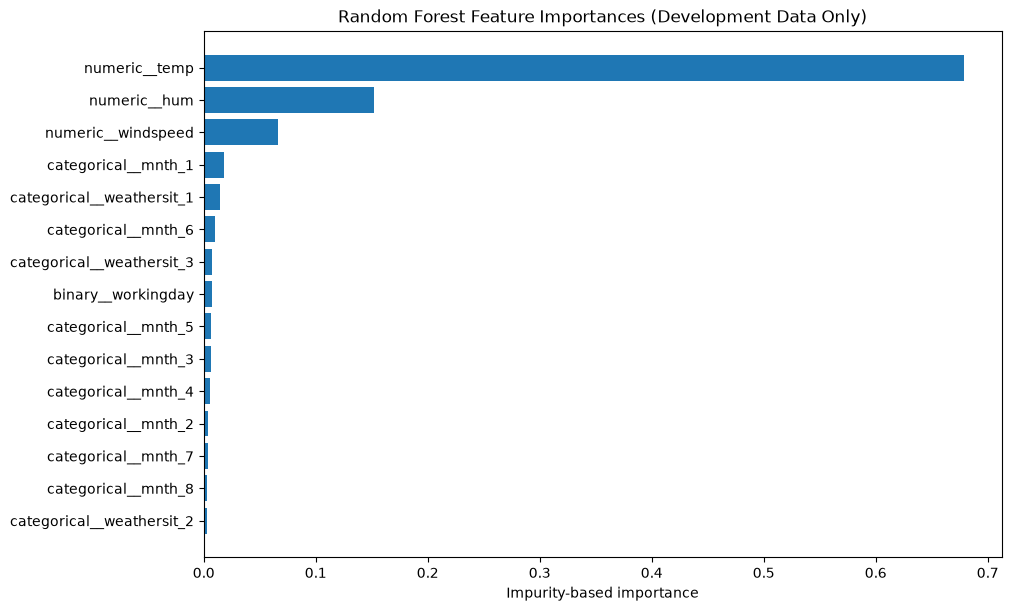

In [15]:
forest_diagnostics = candidate_pipeline('Random forest')
forest_diagnostics.fit(features_train, target_train)
forest_preprocessor = forest_diagnostics.named_steps['preprocess']
forest_estimator = forest_diagnostics.named_steps['model']
encoded_feature_names = forest_preprocessor.get_feature_names_out()
forest_importances = pd.DataFrame({
    'feature': encoded_feature_names,
    'importance': forest_estimator.feature_importances_,
}).sort_values('importance', ascending=False).reset_index(drop=True)
display(forest_importances.head(15).round(3))
forest_importances.to_csv(tables_directory / 'random_forest_feature_importance.csv', index=False)
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
top_features = forest_importances.head(15).iloc[::-1]
ax.barh(top_features['feature'], top_features['importance'])
ax.set(title='Random Forest Feature Importances (Development Data Only)', xlabel='Impurity-based importance')
fig.savefig(figures_directory / 'random_forest_importances.png', dpi=150, bbox_inches='tight')
plt.show()


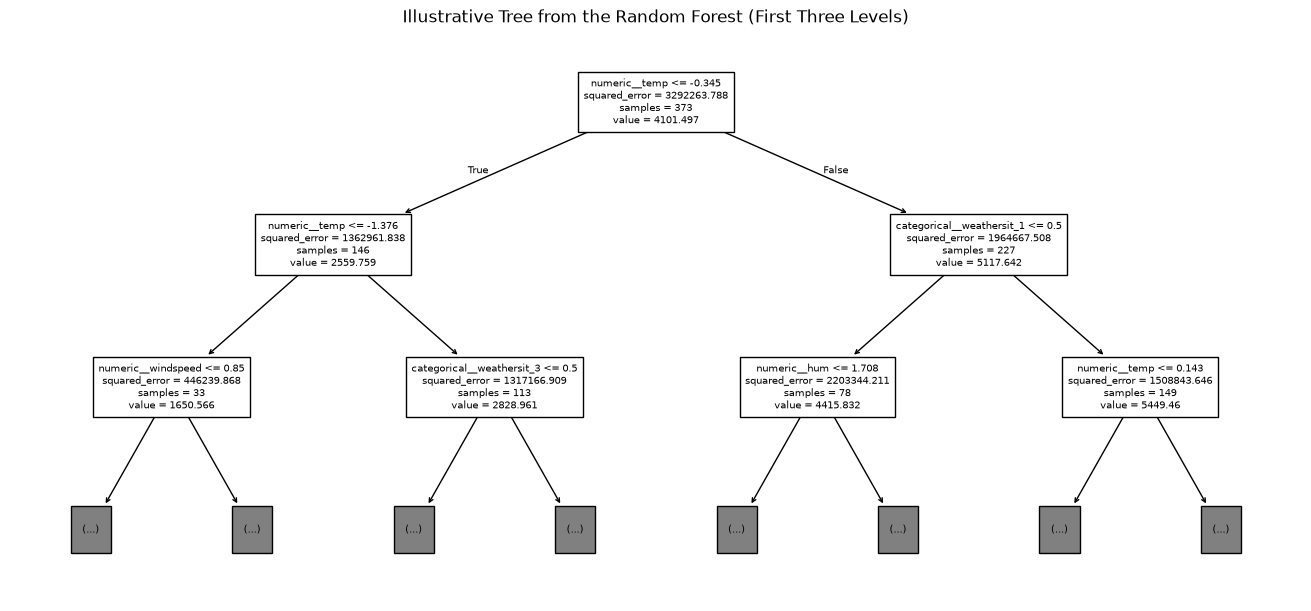

In [16]:
fig, ax = plt.subplots(figsize=(13, 6), constrained_layout=True)
plot_tree(forest_estimator.estimators_[0], max_depth=2, ax=ax, fontsize=7,
          feature_names=list(encoded_feature_names), filled=False)
ax.set_title('Illustrative Tree from the Random Forest (First Three Levels)')
fig.savefig(figures_directory / 'random_forest_tree_excerpt.png', dpi=150, bbox_inches='tight')
plt.show()


## 8. Final Model Selection and One-Time Holdout Evaluation

The winner is the predefined candidate with the lowest **mean development CV RMSE**. No model has been selected using the holdout labels. The holdout is evaluated once and reported as a realistic warning if performance is weak.

**Cross-version caveat:** The same chronological test period was already inspected in the earlier v1 pilot. Although each version selects its winner using training-only CV and computes test metrics once per run, the holdout is no longer fully independent across project iterations. Treat its metrics as exploratory confirmation, not an unbiased estimate of eventual deployment performance. Future claims require an independent period or genuinely external data.


In [17]:
selected_model_name = cv_records[0]['model']
selected_pipeline = candidate_pipeline(selected_model_name)
selected_pipeline.fit(features_train, target_train)
test_predictions = selected_pipeline.predict(features_test)

holdout_rmse = float(np.sqrt(mean_squared_error(target_test, test_predictions)))
holdout_mae = float(mean_absolute_error(target_test, test_predictions))
holdout_r2 = float(r2_score(target_test, test_predictions))
print('Development CV winner:', selected_model_name)
print(f'Holdout RMSE: {holdout_rmse:,.2f} | MAE: {holdout_mae:,.2f} | R²: {holdout_r2:.3f}')

holdout_results = pd.DataFrame({
    'date': test_dates.dt.strftime('%Y-%m-%d').to_numpy(),
    'observed_rentals': target_test.to_numpy(),
    'estimated_rentals': np.round(test_predictions, 2),
})
holdout_results.to_csv(tables_directory / 'holdout_predictions.csv', index=False)


Development CV winner: Polynomial ridge (degree 2)
Holdout RMSE: 2,101.41 | MAE: 1,968.90 | R²: -0.257


### 8.1. Observed versus Estimated Demand

This is the only test-period comparison within this notebook execution (but the period was also examined in pilot v1). The test metrics are not used to adjust or re-rank the candidates. Performance is evaluated for the same-day-weather estimation task, not an operational next-day forecast.


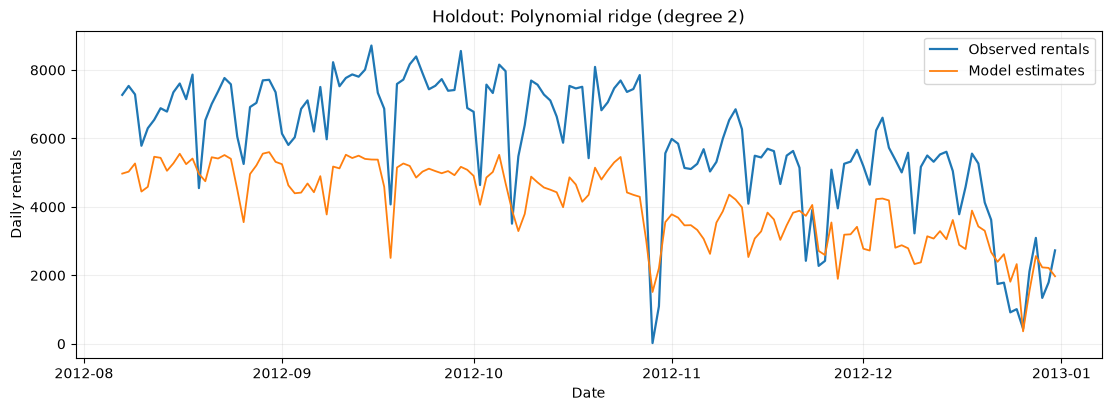

Development CV winner: Polynomial ridge (degree 2); mean RMSE 1,431.3.
Final holdout RMSE: 2,101.4; MAE: 1,968.9; R²: -0.257.
These are conditional same-day-weather estimates, not validated day-ahead forecasts.


In [18]:
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
ax.plot(test_dates, target_test, label='Observed rentals', linewidth=1.6)
ax.plot(test_dates, test_predictions, label='Model estimates', linewidth=1.3)
ax.set(title=f'Holdout: {selected_model_name}', xlabel='Date', ylabel='Daily rentals')
ax.grid(alpha=0.2)
ax.legend()
fig.savefig(figures_directory / 'holdout_predictions.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Development CV winner: {selected_model_name}; mean RMSE {cv_records[0]["cv_mean_rmse"]:,.1f}.')
print(f'Final holdout RMSE: {holdout_rmse:,.1f}; MAE: {holdout_mae:,.1f}; R²: {holdout_r2:.3f}.')
print('These are conditional same-day-weather estimates, not validated day-ahead forecasts.')

## 9. Conclusions, Implications, and Limitations

**Analytical interpretation:** The rider-segment and weather/calendar summaries help characterize the historical dataset, while cross-validation documents how selected regression approaches behave across later development windows. Those associations may help frame hypotheses for staffing, bicycle rebalancing and station availability, but **no operational effect or causal mechanism is established**.

**Limitations:**
- **Repeated project iteration:** This holdout was used in the earlier pilot. Results are transparent but should not be called a never-seen external test across project revisions.
- **Weather timing:** Same-day recorded weather is not an operational day-ahead forecast feature unless a corresponding weather forecast is supplied.
- **Historical coverage:** One city over 2011–2012 cannot establish contemporary or cross-city generalization.
- **CV uncertainty:** Four expanding-window validation folds provide limited evidence, especially in a changing time series.
- **Model dependence:** Feature importance and group means are not causal effects; effects may overlap.
- **Tuning:** The compact GridSearch demonstration is not used to select the reported holdout model.
- **Historical notebook:** Earlier regression scores relied on random train/test splitting, leaky normalization and a mislabeled SVR prediction; do not compare those numbers directly with this revised protocol.

The final holdout evaluation must be interpreted using its actual RMSE, MAE and R², not by claiming that a particular model is universally best.


## 10. Export Daily Metrics

Daily metrics are exported here; the combined HTML is generated after the hourly section completes, so fresh clones do not require pre-existing hourly outputs. Outputs are regenerated when this notebook runs; previous versions remain outside the local project if you want archival comparisons.


In [ ]:
metrics_payload = {
    'data': {
        'records': int(len(bike_data)),
        'date_start': bike_data['dteday'].min().strftime('%Y-%m-%d'),
        'date_end': bike_data['dteday'].max().strftime('%Y-%m-%d'),
        'total_rentals': int(bike_data['cnt'].sum()),
        'annual_totals': {str(year): int(value) for year, value in annual_summary['sum'].items()},
        'rider_totals': {key: int(rental_totals[key]) for key in ['casual', 'registered']},
        'weather_daily_means': {str(key): float(value) for key, value
                                in bike_data.groupby('weathersit')['cnt'].mean().items()},
    },
    'methodology': {
        'task': 'retrospective conditional demand estimation using same-day weather',
        'train_size': int(len(features_train)),
        'holdout_size': int(len(features_test)),
        'train_end_date': bike_data['dteday'].iloc[train_end - 1].strftime('%Y-%m-%d'),
        'holdout_start_date': test_dates.iloc[0].strftime('%Y-%m-%d'),
        'cv': 'TimeSeriesSplit(n_splits=4)',
        'features': feature_names,
        'excluded_target_components': ['casual', 'registered'],
        'tuning_note': 'Separate training-only GridSearch demonstration; tuned estimators not evaluated on holdout',
    },
    'validation': {
        'selected_model': selected_model_name,
        'candidate_cv': cv_records,
        'holdout': {'rmse': holdout_rmse, 'mae': holdout_mae, 'r2': holdout_r2},
    },
    'source': {
        'name': 'UCI Machine Learning Repository — Bike Sharing',
        'url': 'https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset',
        'doi': '10.24432/C5W894',
        'license': 'CC BY 4.0',
    },
}
(project_directory / 'outputs' / 'metrics.json').write_text(
    json.dumps(metrics_payload, ensure_ascii=False, indent=2) + '\n', encoding='utf-8'
)


## 11. Hourly Analysis — Demand, Behavior, and Regression

**Dataset:** `datasets/hour.csv` (same UCI source, 2011–2012). This section
complements the daily analysis above **in the same notebook**. Both tables
represent the same underlying rentals: their totals must not be added.

**Research questions:** At what times is demand highest? How does the rider mix
change through the day? Do working and non-working days exhibit different
patterns? How do hourly regression candidates perform on a later time window?

Models below estimate demand conditionally on **observed same-hour weather**;
they are *not* a validated real-time or day-ahead forecast. Historical
patterns alone do not establish causal effects or modern-day applicability.

### 11.1. Hourly data ingestion and consistency checks

Each observation represents a recorded date–hour. The original UCI source
may omit some date–hour combinations, so missing clock-hours are **not**
filled with invented zero counts. Cross-granularity checks compare daily
totals against sums of hourly records without pooling the two tables.

In [ ]:
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor

hourly_source = project_directory / 'datasets' / 'hour.csv'
if not hourly_source.is_file():
    raise FileNotFoundError(
        f'Missing {hourly_source}. Copy the original UCI hour.csv into the '
        'existing datasets/ folder and rerun this notebook.'
    )
hourly_data = pd.read_csv(hourly_source, parse_dates=['dteday'])
hourly_columns = {'instant', 'dteday', 'hr', 'mnth', 'weekday', 'holiday',
                  'workingday', 'weathersit', 'temp', 'hum', 'windspeed',
                  'casual', 'registered', 'cnt'}
assert hourly_columns.issubset(hourly_data), 'Unexpected hourly source schema.'
assert not hourly_data[list(hourly_columns)].isna().any().any(), 'Hourly missing values.'
hourly_data = hourly_data.sort_values(['dteday', 'hr', 'instant']).reset_index(drop=True)
assert hourly_data['hr'].between(0, 23).all(), 'Invalid hour code.'
assert not hourly_data.duplicated(['dteday', 'hr']).any(), 'Duplicate date/hour keys.'
assert hourly_data['cnt'].ge(0).all(), 'Negative rentals.'
assert (hourly_data['cnt'] == hourly_data['casual'] + hourly_data['registered']).all()
assert ((hourly_data['dteday'].dt.dayofweek + 1) % 7).eq(hourly_data['weekday']).all()

hourly_per_day = hourly_data.groupby('dteday')[['cnt', 'casual', 'registered']].sum()
daily_for_check = bike_data.set_index('dteday')[['cnt', 'casual', 'registered']]
assert hourly_per_day.index.equals(daily_for_check.index), 'Date coverage differs.'
assert hourly_per_day.equals(daily_for_check.astype('int64')), \
    'Hourly aggregation does not reproduce the published daily rental totals.'

hourly_coverage = hourly_data.groupby('dteday')['hr'].nunique()
hourly_incomplete_days = int((hourly_coverage < 24).sum())
hourly_missing_clock_hours = int((24 - hourly_coverage).sum())
print(f'Hourly rows: {len(hourly_data):,} | distinct days: {len(hourly_coverage)}')
print(f'Days with fewer than 24 recorded hours: {hourly_incomplete_days}')
print(f'Missing clock-hour combinations: {hourly_missing_clock_hours}')
print('Daily/hourly totals reconcile exactly: yes')
display(hourly_data[['cnt', 'casual', 'registered', 'temp', 'hum', 'windspeed']].describe().round(2))


### 11.2. Rental volume by hour and rider segment

Plots display **mean rentals per recorded hour** so they are not biased
toward hours appearing more often in the dataset. Separate casual and
registered segments help distinguish commuting-like and leisure-like
demand patterns, but the reason for an individual trip is unobserved.

In [ ]:
hourly_figures = project_directory / 'outputs' / 'hourly' / 'figures'
hourly_tables = project_directory / 'outputs' / 'hourly' / 'tables'
hourly_figures.mkdir(parents=True, exist_ok=True)
hourly_tables.mkdir(parents=True, exist_ok=True)

hourly_means = hourly_data.groupby('hr')[['cnt', 'casual', 'registered']].mean().reindex(range(24))
hourly_means.to_csv(hourly_tables / 'mean_rentals_by_hour.csv')
fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
for col, label in [('cnt', 'Total'), ('casual', 'Casual'), ('registered', 'Registered')]:
    ax.plot(hourly_means.index, hourly_means[col], marker='o', markersize=3, label=label)
ax.set(xlabel='Hour of day', ylabel='Mean rentals per recorded hour',
       title='Hourly rental demand by rider segment', xticks=range(0, 24, 2))
ax.legend()
fig.savefig(hourly_figures / 'hourly_rider_segments.png', dpi=150, bbox_inches='tight')
plt.show()
display(hourly_means.round(1))


### 11.3. Heatmap: day of week × hour

Weekday 0 corresponds to Sunday. Each heatmap cell contains the mean
rental count for recorded observations in that weekday/hour combination.

In [ ]:
hourly_heatmap = hourly_data.pivot_table(
    index='weekday', columns='hr', values='cnt', aggfunc='mean'
).reindex(index=range(7), columns=range(24))
fig, ax = plt.subplots(figsize=(13, 5), constrained_layout=True)
heat = ax.imshow(hourly_heatmap.to_numpy(), aspect='auto', cmap='YlOrRd')
ax.set(title='Mean hourly rentals · weekday × hour', xlabel='Hour of day',
       ylabel='Day of week', xticks=range(0, 24, 2), yticks=range(7),
       yticklabels=['Sun', 'Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat'])
fig.colorbar(heat, ax=ax, label='Mean rentals')
fig.savefig(hourly_figures / 'weekday_hour_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()


### 11.4. Working-day versus non-working-day profiles

This comparison uses the dataset's `workingday` indicator: non-working
days include weekends **and holidays**, not weekends alone.

In [ ]:
hourly_workday = hourly_data.groupby(['hr', 'workingday'])['cnt'].mean().unstack()
hourly_workday = hourly_workday.reindex(range(24))
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
for flag, label in [(0, 'Non-working day'), (1, 'Working day')]:
    ax.plot(hourly_workday.index, hourly_workday[flag], marker='.', label=label)
ax.set(title='Hourly demand by working-day category', xlabel='Hour of day',
       ylabel='Mean rentals per recorded hour', xticks=range(0, 24, 2))
ax.legend()
fig.savefig(hourly_figures / 'workingday_hourly_profiles.png', dpi=150, bbox_inches='tight')
plt.show()
print('Historical registered share:',
      f"{100 * hourly_data['registered'].sum() / hourly_data['cnt'].sum():.1f}%")


### 11.5. Regression candidates with day-boundary temporal validation

The last 20% of **unique dates** form the hourly holdout. Cross-validation
splits the earlier unique dates into expanding training and later validation
windows, excluding one full intervening day. No date is shared across a
training/validation or development/holdout boundary. Transformations are
fitted only on the training fold using scikit-learn pipelines.

`casual` and `registered` are excluded as target components. The identifier,
date key and year indicator are excluded from predictors. Calendar/weather
features are observational; this is not an operational demand forecast.

In [ ]:
hourly_numeric = ['temp', 'hum', 'windspeed']
hourly_categorical = ['hr', 'mnth', 'weekday', 'weathersit']
hourly_binary = ['holiday', 'workingday']
hourly_features = hourly_numeric + hourly_categorical + hourly_binary
hourly_X = hourly_data[hourly_features].copy()
hourly_y = hourly_data['cnt'].copy()
hourly_dates = hourly_data['dteday']
hourly_unique_dates = pd.DatetimeIndex(hourly_dates.drop_duplicates())
hourly_split_date = hourly_unique_dates[int(len(hourly_unique_dates) * 0.80)]
hourly_train_mask = hourly_dates < hourly_split_date
hourly_test_mask = ~hourly_train_mask
hourly_X_train = hourly_X.loc[hourly_train_mask]
hourly_X_test = hourly_X.loc[hourly_test_mask]
hourly_y_train = hourly_y.loc[hourly_train_mask]
hourly_y_test = hourly_y.loc[hourly_test_mask]
hourly_train_dates = hourly_unique_dates[hourly_unique_dates < hourly_split_date]
assert hourly_dates.loc[hourly_train_mask].max() < hourly_dates.loc[hourly_test_mask].min()

hourly_preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), hourly_numeric),
    ('categories', OneHotEncoder(handle_unknown='ignore', sparse_output=False), hourly_categorical),
    ('binary', 'passthrough', hourly_binary),
], sparse_threshold=0)
hourly_candidates = {
    'Ridge': Ridge(alpha=10.0),
    'Random forest': RandomForestRegressor(
        n_estimators=90, min_samples_leaf=3, random_state=random_seed, n_jobs=-1),
    'Histogram gradient boosting': HistGradientBoostingRegressor(
        max_iter=130, learning_rate=0.07, random_state=random_seed),
}
hourly_date_cv = TimeSeriesSplit(n_splits=4, gap=1)
hourly_cv_results = []
for hourly_name, hourly_estimator in hourly_candidates.items():
    hourly_fold_rmses = []
    for hourly_train_days, hourly_valid_days in hourly_date_cv.split(hourly_train_dates):
        hourly_fold_train_dates = hourly_train_dates[hourly_train_days]
        hourly_fold_valid_dates = hourly_train_dates[hourly_valid_days]
        assert hourly_fold_train_dates.max() < hourly_fold_valid_dates.min()
        hourly_fold_train_mask = hourly_dates.loc[hourly_train_mask].isin(hourly_fold_train_dates)
        hourly_fold_valid_mask = hourly_dates.loc[hourly_train_mask].isin(hourly_fold_valid_dates)
        hourly_model = Pipeline([
            ('preprocess', clone(hourly_preprocessor)),
            ('regressor', clone(hourly_estimator)),
        ])
        hourly_model.fit(hourly_X_train.loc[hourly_fold_train_mask],
                         hourly_y_train.loc[hourly_fold_train_mask])
        hourly_fold_pred = hourly_model.predict(hourly_X_train.loc[hourly_fold_valid_mask])
        hourly_fold_rmse = np.sqrt(mean_squared_error(
            hourly_y_train.loc[hourly_fold_valid_mask], hourly_fold_pred))
        hourly_fold_rmses.append(float(hourly_fold_rmse))
    hourly_cv_results.append({
        'model': hourly_name,
        'cv_mean_rmse': float(np.mean(hourly_fold_rmses)),
        'cv_std_rmse': float(np.std(hourly_fold_rmses)),
        'cv_fold_rmses': hourly_fold_rmses,
    })
hourly_comparison = pd.DataFrame(hourly_cv_results).sort_values('cv_mean_rmse').reset_index(drop=True)
display(hourly_comparison[['model', 'cv_mean_rmse', 'cv_std_rmse']].round(2))
print('Hourly holdout starts:', hourly_split_date.date())


### 11.6. Selected-model holdout and reproducible hourly exports

The lowest training-period CV RMSE determines the candidate. The later
chronological holdout is evaluated after selection and is not used for
tuning. As this project is iterative, the holdout should not be described
as fully independent across future notebook revisions.

In [ ]:
hourly_best_name = str(hourly_comparison.iloc[0]['model'])
hourly_selected = Pipeline([
    ('preprocess', clone(hourly_preprocessor)),
    ('regressor', clone(hourly_candidates[hourly_best_name])),
])
hourly_selected.fit(hourly_X_train, hourly_y_train)
hourly_predictions = hourly_selected.predict(hourly_X_test)
hourly_metrics = {
    'model': hourly_best_name,
    'cv_mean_rmse': float(hourly_comparison.iloc[0]['cv_mean_rmse']),
    'holdout_rmse': float(np.sqrt(mean_squared_error(hourly_y_test, hourly_predictions))),
    'holdout_mae': float(mean_absolute_error(hourly_y_test, hourly_predictions)),
    'holdout_r2': float(r2_score(hourly_y_test, hourly_predictions)),
    'hourly_rows': int(len(hourly_data)),
    'train_rows': int(len(hourly_X_train)),
    'holdout_rows': int(len(hourly_X_test)),
    'holdout_start_date': hourly_split_date.strftime('%Y-%m-%d'),
    'incomplete_days': hourly_incomplete_days,
    'missing_recorded_clock_hours': hourly_missing_clock_hours,
    'scope': 'Retrospective conditional demand estimation using observed same-hour weather',
}
display(pd.DataFrame([hourly_metrics]).round(3))
hourly_comparison.to_csv(hourly_tables / 'hourly_model_comparison.csv', index=False)
pd.DataFrame({
    'date': hourly_dates.loc[hourly_test_mask].dt.strftime('%Y-%m-%d').to_numpy(),
    'hour': hourly_data.loc[hourly_test_mask, 'hr'].to_numpy(),
    'observed_rentals': hourly_y_test.to_numpy(),
    'estimated_rentals': np.round(hourly_predictions, 2),
}).to_csv(hourly_tables / 'hourly_holdout_predictions.csv', index=False)
(project_directory / 'outputs' / 'hourly' / 'metrics.json').write_text(
    json.dumps(hourly_metrics, indent=2, ensure_ascii=False) + '\n', encoding='utf-8'
)
hourly_chart_rows = min(len(hourly_y_test), 24 * 7)
fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
ax.plot(range(hourly_chart_rows), hourly_y_test.iloc[:hourly_chart_rows].to_numpy(),
        label='Observed', linewidth=1.8)
ax.plot(range(hourly_chart_rows), hourly_predictions[:hourly_chart_rows],
        label='Estimated', linewidth=1.5, alpha=0.8)
ax.set(title='Hourly holdout — first seven recorded days (up to 168 rows)',
       xlabel='Successive recorded hourly rows', ylabel='Rentals')
ax.legend()
fig.savefig(hourly_figures / 'hourly_holdout.png', dpi=150, bbox_inches='tight')
plt.show()

# Generate the combined HTML only after the hourly outputs exist.
from report_builder import build_html_report
build_html_report(metrics_path=project_directory / 'outputs' / 'metrics.json',
                  daily_data_path=data_path,
                  predictions_path=tables_directory / 'holdout_predictions.csv',
                  output_path=report_directory / 'index.html')


### 11.7. Interpretation, limitations, and reporting status

- Hourly peaks can motivate **hypotheses** for fleet balancing and staffing;
  no individual trip purpose or causal effect is observed.
- `workingday = 0` includes both holidays and weekends.
- Daily/hourly totals describe **overlapping records**; never add them.
- Missing date–hour rows are reported and not assumed to indicate zero demand.
- Preprocessing is fitted inside temporal folds; a one-day CV gap improves
  separation, though serial dependence and distribution shifts remain.
- Weather features are measured for the target hour, so this does not
  establish next-hour or next-day operational forecast performance.
- The existing `reports/index.html` is **still daily-only at this stage**.
  Integrating the hourly outputs into the interactive HTML is the next
  separate task, after executing and validating this notebook.
- No automatic profiling report or profiling dependency is included.

## 12. References, Methodology, and Reproducibility

- [UCI Bike Sharing Dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), Fanaee-T and Gama; DOI 10.24432/C5W894. Dataset license: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
- Fanaee-T, H. and Gama, J. (2013). *Event labeling combining ensemble detectors and background knowledge*. Progress in Artificial Intelligence. DOI: [10.1007/s13748-013-0040-3](https://doi.org/10.1007/s13748-013-0040-3).
- [scikit-learn: Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html); [TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html); [Common pitfalls: data leakage](https://scikit-learn.org/stable/common_pitfalls.html).
- [Machine Learning Knowledge Base](https://github.com/eduardojr-pereira/data-science-knowledge-base/tree/main/05_machine_learning) and [Data Analysis & Visualization Knowledge Base](https://github.com/eduardojr-pereira/data-science-knowledge-base/tree/main/02_data_analysis_visualization).

**Reproduce:** Put both `day.csv` and `hour.csv` in the `datasets/` folder; activate the project environment; open the notebook; choose **Restart Kernel → Run All Cells**; verify regenerated CSV, JSON, PNG and HTML outputs. The original historical notebook and source archive are preserved outside this distribution. **This revision is a technical draft pending user approval, not a published portfolio artifact.**
